# Data Structures & Algorithms: Graphs

> **Who is this for?** Beginners who know Python, recursion, stacks, queues and heaps and want to understand the most versatile data structure in computer science; and university students preparing for algorithms exams or coding interviews.
>
> **What you will learn**
> - Graph vocabulary: directed/undirected, weighted, degree, path, cycle, connected components, DAG, bipartite.
> - Three representations (adjacency matrix, adjacency list, edge list) and when to use each.
> - **BFS** and **DFS** (recursive and iterative) with pictures; connected components; cycle detection (undirected and directed); bipartite check.
> - **Topological sort** (Kahn's algorithm and DFS-based).
> - **Shortest paths:** BFS, **Dijkstra** (and why negative edges break it), **Bellman-Ford** (negative-cycle detection), **Floyd-Warshall**, and 0-1 BFS.
> - **Minimum spanning trees:** Kruskal with **Union-Find** (path compression + union by rank) and Prim.
> - **Strongly connected components** (Kosaraju and Tarjan), bridges and articulation points.
> - Grid problems: number of islands and rotting oranges.
> - Every algorithm is written from scratch and **checked against networkx on random graphs**.
>
> **Prerequisites**
> - [Python basics](../../01_Python/01_basic.ipynb) (classes, dictionaries, sets).
> - Recursion and Big-O: [01 · Complexity Analysis and Recursion](01_complexity_analysis_and_recursion.ipynb).
> - Stacks, queues and deques: [05 · Linked Lists, Stacks and Queues](05_linked_lists_stacks_queues.ipynb); trees and heaps: [06 · Trees, BSTs and Heaps](06_trees_bst_and_heaps.ipynb).
>
> **Time needed:** about 4 to 5 hours (reading + running + practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library, NumPy, pandas, matplotlib, networkx.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*. It is not required for the rest of the course, but it is recommended for BS/MS AI students and for interview preparation.

## Explained simply

A **graph** is simply a set of things (called **nodes**) and the connections between them (called **edges**). A road map is a graph: cities are nodes and roads are edges; a social network is a graph: people are nodes and friendships are edges. Many everyday questions are graph questions: "what is the quickest route home?" (shortest path), "can everyone in this group reach each other?" (connectivity), "in what order should I do my chores if some must come first?" (topological sort), "what is the cheapest way to connect every house to the internet?" (minimum spanning tree). **BFS** explores like ripples in a pond, checking everything one step away before anything two steps away; **DFS** explores like walking through a maze, going as deep as possible and backtracking at dead ends. Sat-navs, Google Maps, recommendation systems, knowledge graphs for LLMs and AI agent workflows are all built on these ideas.

**Tiny example.** Four friends: Ana knows Ben and Cai, Ben knows Dev. Who is closest to Ana? BFS from Ana finds Ben and Cai at 1 step, then Dev at 2 steps (through Ben). Now give the roads lengths: Home→Shop is 4 km, Home→Park is 1 km and Park→Shop is 2 km. Dijkstra's algorithm discovers that going through the park (1 + 2 = 3 km) beats the direct road (4 km).

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Graph | dots (nodes) joined by lines (edges) | road maps, social networks, the web, knowledge graphs |
| BFS / DFS | explore in ripples / explore deep then backtrack | "people you may know", maze solving, web crawlers, AI search |
| Shortest path | the cheapest route between two points | Google Maps, delivery routing, robot navigation, game AI |

## Table of contents
1. [Setup: a Graph class and drawing helpers](#setup)
2. [Terminology](#terminology)
3. [Representations](#representations)
4. [BFS and DFS](#bfs-dfs)
5. [Connected components, cycles, bipartite graphs](#components)
6. [Topological sort](#topo)
7. [Shortest paths](#shortest)
8. [Minimum spanning trees and Union-Find](#mst)
9. [Strongly connected components, bridges, articulation points](#scc)
10. [Grid graphs](#grids)
11. [Complexity summary](#summary)
12. [Connections: classical AI search and modern AI](#modern-ai)
13. [Recap, practice problems, further reading](#recap)

<a id="setup"></a>
## 1. Setup: a `Graph` class and drawing helpers

> **In plain English:** we build one small `Graph` class and a drawing helper that every later section reuses.

Our `Graph` stores an **adjacency list** as a dictionary of dictionaries: `adj[u][v] = weight`. Python dictionaries remember insertion order, so neighbours are always visited in the order the edges were added. That makes our algorithms deterministic and lets us compare traversal *orders* exactly with networkx (which uses the same dict-of-dicts design internally).

networkx 3.7


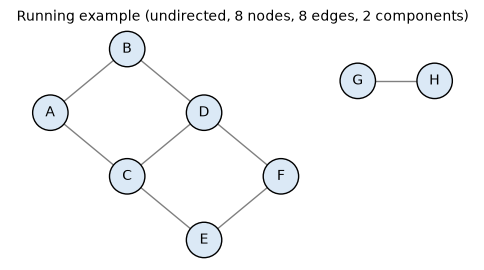

In [1]:
import random                                   # random graphs for testing
import math                                     # infinity, logs
import heapq                                    # priority queue for Dijkstra and Prim
import itertools                                # combinations
import sys
from collections import deque, defaultdict      # queues for BFS

import numpy as np                              # adjacency matrices
import pandas as pd                             # trace tables
import matplotlib.pyplot as plt                 # drawings
import networkx as nx                           # drawing + reference implementations

INF = math.inf
random.seed(42)
np.random.seed(42)
sys.setrecursionlimit(10_000)                   # our recursive DFS runs on graphs of a few hundred nodes
print("networkx", nx.__version__)


class Graph:
    '''Adjacency-list graph: adj[u] = {v: weight}. Directed or undirected, simple (no parallel edges).'''

    def __init__(self, directed=False):
        self.directed = directed
        self.adj = {}                           # node -> {neighbour: weight}
        self._log = []                          # edges in insertion order (to rebuild an identical networkx graph)

    def add_node(self, u):
        self.adj.setdefault(u, {})

    def add_edge(self, u, v, w=1):
        self.add_node(u); self.add_node(v)
        self.adj[u][v] = w
        if not self.directed:
            self.adj[v][u] = w                  # undirected: store both directions
        self._log.append((u, v, w))

    @classmethod
    def from_edges(cls, edges, directed=False, nodes=()):
        g = cls(directed)
        for u in nodes:
            g.add_node(u)
        for e in edges:
            g.add_edge(*e)
        return g

    def nodes(self):
        return list(self.adj)

    def neighbors(self, u):
        return list(self.adj[u])

    def edges(self):
        '''List of (u, v, w); undirected edges are listed once.'''
        out, seen = [], set()
        for u, nbrs in self.adj.items():
            for v, w in nbrs.items():
                if self.directed:
                    out.append((u, v, w))
                elif (v, u) not in seen:
                    seen.add((u, v)); out.append((u, v, w))
        return out

    def reversed(self):
        '''Same nodes, every directed edge flipped (used by Kosaraju).'''
        r = Graph(directed=True)
        for u in self.adj:
            r.add_node(u)
        for u, v, w in self.edges():
            r.add_edge(v, u, w)
        return r

    def to_networkx(self):
        G = nx.DiGraph() if self.directed else nx.Graph()
        G.add_nodes_from(self.adj)
        for u, v, w in self._log:
            G.add_edge(u, v, weight=w)          # same insertion order -> same neighbour order
        return G


def random_graph(n, m, rng, directed=False, weight=None, connected=False):
    '''n nodes 0..n-1, about m distinct edges; weight() draws a weight (default 1).'''
    weight = weight or (lambda: 1)
    max_m = n * (n - 1) // (1 if directed else 2)
    edges, used = [], set()
    def add(u, v):
        key = (u, v) if directed else frozenset((u, v))
        if u != v and key not in used:
            used.add(key); edges.append((u, v, weight()))
    if connected:                               # random spanning tree first
        order = list(range(n)); rng.shuffle(order)
        for i in range(1, n):
            add(order[rng.randrange(i)], order[i])
    while len(edges) < min(m, max_m):
        add(rng.randrange(n), rng.randrange(n))
    return Graph.from_edges(edges, directed, nodes=range(n))


def draw_graph(g, ax, pos=None, title="", node_colors=None, highlight=(), labels=None, edge_labels=False, node_size=650):
    '''Draw a Graph; highlight = edges to draw thick and red.'''
    G = g.to_networkx()
    pos = pos or nx.spring_layout(G, seed=3)
    cols = [node_colors.get(v, "#dbe9f6") if node_colors else "#dbe9f6" for v in G]
    hl = {(u, v) for u, v in highlight} | ({(v, u) for u, v in highlight} if not g.directed else set())
    ecol = ["tab:red" if (u, v) in hl else "gray" for u, v in G.edges()]
    width = [3 if (u, v) in hl else 1 for u, v in G.edges()]
    nx.draw_networkx(G, pos, ax=ax, node_color=cols, edgecolors="black", node_size=node_size, edge_color=ecol,
                     width=width, labels=labels, font_size=10,
                     **({"connectionstyle": "arc3,rad=0.08", "arrowsize": 15} if g.directed else {}))
    if edge_labels:
        nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels={(u, v): d["weight"] for u, v, d in G.edges(data=True)},
                                     font_size=9, **({"connectionstyle": "arc3,rad=0.08"} if g.directed else {}))
    ax.set_title(title, fontsize=10); ax.axis("off")
    return pos


# The running example: an undirected graph with two components.
EX_EDGES = [("A", "B"), ("A", "C"), ("B", "D"), ("C", "D"), ("C", "E"), ("D", "F"), ("E", "F"), ("G", "H")]
ex = Graph.from_edges(EX_EDGES)
EX_POS = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2, 0), "E": (2, -2), "F": (3, -1), "G": (4, 0.5), "H": (5, 0.5)}
fig, ax = plt.subplots(figsize=(6, 3))
draw_graph(ex, ax, EX_POS, "Running example (undirected, 8 nodes, 8 edges, 2 components)")
plt.show()

<a id="terminology"></a>
## 2. Terminology

> **In plain English:** the vocabulary of graphs: dots, lines, directions, weights, loops and groups.

### 2.1 Intuition

A **graph** is a set of things plus the connections between them: cities and roads, people and friendships, web pages and links, tasks and "must happen before" rules, atoms and bonds. Trees (previous notebook) are a special case of graphs.

### 2.2 Definitions

- A **graph** G = (V, E) has a set of **vertices** (nodes) V and a set of **edges** E. We write n = |V| and m = |E|.
- **Undirected** edge {u, v}: the connection goes both ways (friendship). **Directed** edge (u, v) or u → v: one way only (following someone, a one-way street). A directed graph is a **digraph**.
- **Weighted** graph: every edge has a number (distance, cost, time, capacity).
- **Adjacent** vertices are joined by an edge; they are **neighbours**.
- **Degree** deg(v) = number of edges touching v (undirected). In a digraph: **in-degree** (edges coming in) and **out-degree** (edges going out).
- **Handshake lemma:** Σ deg(v) = 2m in an undirected graph (every edge is counted at both ends). In a digraph Σ in-degree = Σ out-degree = m.
- A **path** is a sequence of vertices where consecutive ones are adjacent; a **simple path** repeats no vertex. Its **length** is the number of edges (or the sum of weights).
- A **cycle** is a path of length ≥ 1 that starts and ends at the same vertex (in undirected simple graphs, length ≥ 3) with no other repeats. A graph with no cycles is **acyclic**.
- An undirected graph is **connected** if every pair of vertices is joined by a path. Its maximal connected pieces are the **connected components**. A digraph is **strongly connected** if every vertex can reach every other following edge directions.
- A **tree** is a connected acyclic undirected graph (it has exactly n − 1 edges); a **forest** is an acyclic graph (a union of trees).
- A **DAG** (directed acyclic graph) is a digraph with no directed cycle: task dependencies, spreadsheets, neural-network computation graphs.
- A graph is **bipartite** if its vertices can be split into two groups so that every edge goes *between* the groups (users and products, students and courses). Equivalent: it has **no odd-length cycle**.
- **Sparse** graphs have m = O(n) edges; **dense** graphs have m close to the maximum n(n − 1)/2 (undirected) or n(n − 1) (directed).

degrees: {'A': 2, 'B': 2, 'C': 3, 'D': 3, 'E': 2, 'F': 2, 'G': 1, 'H': 1}
sum of degrees = 16 = 2 x edges = 16
digraph out-degrees: {'x': 2, 'y': 1, 'z': 1, 'w': 0} | in-degrees: {'x': 0, 'y': 1, 'z': 2, 'w': 1}


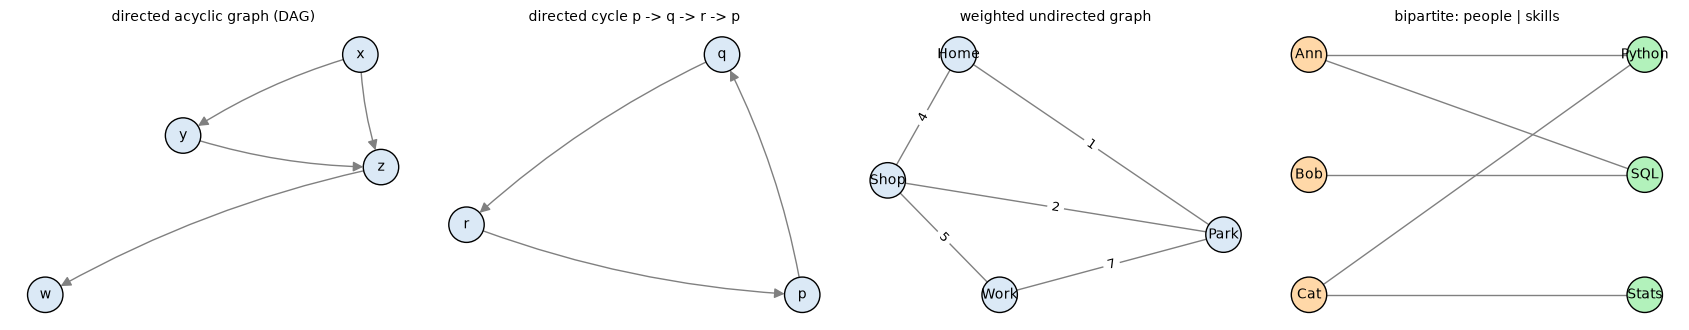

In [2]:
deg = {v: len(ex.adj[v]) for v in ex.nodes()}
print("degrees:", deg)
print("sum of degrees =", sum(deg.values()), "= 2 x edges =", 2 * len(ex.edges()))

dg = Graph.from_edges([("x", "y"), ("y", "z"), ("x", "z"), ("z", "w")], directed=True)
indeg = {v: 0 for v in dg.nodes()}
for u, v, _ in dg.edges():
    indeg[v] += 1
print("digraph out-degrees:", {v: len(dg.adj[v]) for v in dg.nodes()}, "| in-degrees:", indeg)

wg = Graph.from_edges([("Home", "Shop", 4), ("Home", "Park", 1), ("Park", "Shop", 2), ("Shop", "Work", 5), ("Park", "Work", 7)])
cyc = Graph.from_edges([("p", "q"), ("q", "r"), ("r", "p")], directed=True)
bip = Graph.from_edges([("Ann", "Python"), ("Ann", "SQL"), ("Bob", "SQL"), ("Cat", "Python"), ("Cat", "Stats")])

fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
draw_graph(dg, axes[0], title="directed acyclic graph (DAG)")
draw_graph(cyc, axes[1], title="directed cycle p -> q -> r -> p")
draw_graph(wg, axes[2], title="weighted undirected graph", edge_labels=True)
bpos = {"Ann": (0, 2), "Bob": (0, 1), "Cat": (0, 0), "Python": (1, 2), "SQL": (1, 1), "Stats": (1, 0)}
draw_graph(bip, axes[3], bpos, "bipartite: people | skills",
           node_colors={v: ("#ffd8a8" if v in ("Ann", "Bob", "Cat") else "#b2f2bb") for v in bip.nodes()})
plt.tight_layout(); plt.show()

**What just happened?** In the running example the degrees add up to 16 = 2 × 8 edges, as the handshake lemma promises. In the small digraph, x has out-degree 2 and in-degree 0 (a **source**), while w has out-degree 0 (a **sink**). The four pictures show a DAG, a directed cycle, a weighted graph (the cheapest route Home → Shop goes via the Park: 1 + 2 = 3 < 4) and a bipartite graph (every edge joins an orange person to a green skill).

<a id="representations"></a>
## 3. Representations

> **In plain English:** there are three common ways to store a graph in memory, and the right one depends on how many connections there are.

| Representation | What it stores | Space | Is (u, v) an edge? | Iterate neighbours of u | Add edge | Best for |
|---|---|---|---|---|---|---|
| **Adjacency matrix** | n × n table, `M[u][v] = weight` or 0 | **Θ(n²)** | **O(1)** | Θ(n) | O(1) | dense graphs, Floyd-Warshall, linear algebra (GNNs, PageRank) |
| **Adjacency list** | for each u, its neighbours | **Θ(n + m)** | O(deg u) (O(1) average with a set/dict) | **O(deg u)** | O(1) | sparse graphs; BFS, DFS, Dijkstra (the default) |
| **Edge list** | list of (u, v, w) | Θ(m) | O(m) | O(m) | O(1) | Kruskal (sort the edges), Bellman-Ford, file formats |

Most real graphs are **sparse** (a social network user has hundreds of friends, not millions), so the adjacency list is the default. Our `Graph` uses dictionaries for the lists, so the edge test is O(1) on average too.

In [3]:
def to_matrix(g):
    nodes = g.nodes()
    idx = {v: i for i, v in enumerate(nodes)}             # vertex -> row/column number
    M = np.zeros((len(nodes), len(nodes)), dtype=int)
    for u, v, w in g.edges():
        M[idx[u], idx[v]] = w
        if not g.directed:
            M[idx[v], idx[u]] = w                         # symmetric for undirected graphs
    return nodes, M

nodes, M = to_matrix(ex)
display(pd.DataFrame(M, index=nodes, columns=nodes))
print("adjacency list:", {u: list(nb) for u, nb in ex.adj.items()})
print("edge list     :", [(u, v) for u, v, _ in ex.edges()])
assert (M == nx.to_numpy_array(ex.to_networkx(), nodelist=nodes, dtype=int)).all()
assert (M == M.T).all() and (M.sum(axis=1) == [len(ex.adj[v]) for v in nodes]).all()
print("matrix matches networkx; it is symmetric and its row sums are the degrees")

n_users, avg_friends = 1_000_000, 200
m_edges = n_users * avg_friends // 2
print(f"\nsocial network, {n_users:,} users x {avg_friends} friends: matrix needs {n_users**2:,} cells "
      f"(~{n_users**2 / 8 / 1e9:,.0f} GB even at 1 bit per cell); adjacency list stores {2 * m_edges:,} entries")

,A,B,C,D,E,F,G,H
A,0,1,1,0,0,0,0,0
B,1,0,0,1,0,0,0,0
C,1,0,0,1,1,0,0,0
D,0,1,1,0,0,1,0,0
E,0,0,1,0,0,1,0,0
F,0,0,0,1,1,0,0,0
G,0,0,0,0,0,0,0,1
H,0,0,0,0,0,0,1,0


adjacency list: {'A': ['B', 'C'], 'B': ['A', 'D'], 'C': ['A', 'D', 'E'], 'D': ['B', 'C', 'F'], 'E': ['C', 'F'], 'F': ['D', 'E'], 'G': ['H'], 'H': ['G']}
edge list     : [('A', 'B'), ('A', 'C'), ('B', 'D'), ('C', 'D'), ('C', 'E'), ('D', 'F'), ('E', 'F'), ('G', 'H')]
matrix matches networkx; it is symmetric and its row sums are the degrees

social network, 1,000,000 users x 200 friends: matrix needs 1,000,000,000,000 cells (~125 GB even at 1 bit per cell); adjacency list stores 200,000,000 entries


**What just happened?** The matrix is symmetric (undirected), its row sums are the degrees, and it matches `networkx.to_numpy_array`. It is mostly zeros: 16 of 64 cells are used. For a million-user social network the matrix would need 10¹² cells (125 GB even at one bit each), while the adjacency list needs 2 × 10⁸ entries.

<a id="bfs-dfs"></a>
## 4. Breadth-first search (BFS) and depth-first search (DFS)

> **In plain English:** BFS explores in rings like ripples on a pond; DFS dives as deep as it can and backtracks, like walking a maze.

### 4.1 BFS

**Intuition:** drop a stone in a pond; the ripples reach everything at distance 1, then 2, then 3. BFS explores the graph **in layers** using a **FIFO queue**, so in an **unweighted** graph it finds the **shortest path** (fewest edges) from the source to every reachable vertex.

Hand trace from A on the running example (neighbours in alphabetical/insertion order):

| step | dequeue | newly discovered (distance) | queue afterwards |
|---|---|---|---|
| 0 | | A (0) | A |
| 1 | A | B (1), C (1) | B, C |
| 2 | B | D (2) | C, D |
| 3 | C | E (2) | D, E |
| 4 | D | F (3) | E, F |
| 5 | E | – (F already seen) | F |
| 6 | F | – | (empty) |

G and H are never reached: they are in another component.

In [4]:
def bfs(g, s):
    '''Return (visit order, distance dict, parent dict) for BFS from s.'''
    dist, parent, order = {s: 0}, {s: None}, []
    queue = deque([s])
    while queue:
        u = queue.popleft()                    # FIFO: closest undiscovered layer first
        order.append(u)
        for v in g.neighbors(u):
            if v not in dist:                  # mark when DISCOVERED (enqueued), not when dequeued
                dist[v] = dist[u] + 1
                parent[v] = u
                queue.append(v)
    return order, dist, parent

def path_to(parent, t):
    '''Follow parent pointers back from t to the source.'''
    path = []
    while t is not None:
        path.append(t); t = parent[t]
    return path[::-1]

order, dist, parent = bfs(ex, "A")
print("BFS order:", order, "| distances:", dist)
print("shortest path A -> F:", path_to(parent, "F"))

rng = random.Random(1)
for _ in range(300):
    directed = rng.random() < 0.5
    g = random_graph(rng.randint(1, 40), rng.randint(0, 80), rng, directed=directed)
    G = g.to_networkx(); s = rng.randrange(len(g.nodes()))
    o, d, p = bfs(g, s)
    assert d == nx.single_source_shortest_path_length(G, s)
    assert o == [s] + [v for _, v in nx.bfs_edges(G, s)]          # identical visiting order
    assert all(len(path_to(p, t)) - 1 == d[t] for t in d)
print("BFS distances and order match networkx on 300 random (di)graphs")

BFS order: ['A', 'B', 'C', 'D', 'E', 'F'] | distances: {'A': 0, 'B': 1, 'C': 1, 'D': 2, 'E': 2, 'F': 3}
shortest path A -> F: ['A', 'B', 'D', 'F']


BFS distances and order match networkx on 300 random (di)graphs


**What just happened?** BFS visited A, B, C, D, E, F (exactly the hand trace) and found distances A 0, B 1, C 1, D 2, E 2, F 3. Following parent pointers back from F gives the shortest path A → B → D → F. On random graphs BFS matched networkx in both distances and visiting order.

**Complexity:** every vertex is enqueued once and every adjacency-list entry is scanned once: **O(n + m)** time, **O(n)** space.

⚠️ **Common mistake:** marking a vertex as visited when it is *dequeued* instead of when it is *enqueued*. The result is still correct but the same vertex can sit in the queue many times, which can blow up memory on dense graphs.

### 4.2 DFS

**Intuition:** exploring a maze with a ball of string: keep going down a corridor until you hit a dead end, then **backtrack** to the last junction with an unexplored corridor. DFS uses a **stack** (the call stack in the recursive version). It records a **discovery time** when it first enters a vertex and a **finish time** when it has explored everything reachable from it; these times power cycle detection, topological sort and SCCs.

In [5]:
def dfs_recursive(g, s, order=None, visited=None):
    if order is None:
        order, visited = [], set()
    visited.add(s)
    order.append(s)                            # preorder: record on entry
    for v in g.neighbors(s):
        if v not in visited:
            dfs_recursive(g, v, order, visited)   # go deeper before trying the next neighbour
    return order

def dfs_iterative(g, s):
    '''Same visiting order as the recursive version.'''
    order, visited, stack = [], set(), [s]
    while stack:
        u = stack.pop()
        if u in visited:                       # a vertex can be pushed several times; process it once
            continue
        visited.add(u)
        order.append(u)
        for v in reversed(g.neighbors(u)):     # reversed so the FIRST neighbour is popped first
            if v not in visited:
                stack.append(v)
    return order

def dfs_times(g):
    '''Full DFS over all vertices: discovery/finish times and DFS-forest parents.'''
    clock, disc, fin, parent = [0], {}, {}, {}
    def visit(u):
        clock[0] += 1; disc[u] = clock[0]
        for v in g.neighbors(u):
            if v not in disc:
                parent[v] = u
                visit(v)
        clock[0] += 1; fin[u] = clock[0]
    for u in g.nodes():
        if u not in disc:
            parent[u] = None
            visit(u)
    return disc, fin, parent

print("DFS recursive :", dfs_recursive(ex, "A"))
print("DFS iterative :", dfs_iterative(ex, "A"))
disc, fin, dparent = dfs_times(ex)
display(pd.DataFrame({"discovered": disc, "finished": fin, "parent": dparent}).T)

rng = random.Random(2)
for _ in range(300):
    directed = rng.random() < 0.5
    g = random_graph(rng.randint(1, 40), rng.randint(0, 80), rng, directed=directed)
    G = g.to_networkx(); s = rng.randrange(len(g.nodes()))
    rec = dfs_recursive(g, s)
    assert rec == dfs_iterative(g, s) == list(nx.dfs_preorder_nodes(G, s))
    reach = nx.descendants(G, s) | {s} if directed else nx.node_connected_component(G, s)
    assert set(rec) == reach
print("recursive DFS == iterative DFS == networkx dfs_preorder_nodes on 300 random (di)graphs")

DFS recursive : ['A', 'B', 'D', 'C', 'E', 'F']
DFS iterative : ['A', 'B', 'D', 'C', 'E', 'F']


,A,B,D,C,E,F,G,H
discovered,1,2,3,4,5,6,13,14
finished,12,11,10,9,8,7,16,15
parent,None,A,B,D,C,E,None,G


recursive DFS == iterative DFS == networkx dfs_preorder_nodes on 300 random (di)graphs


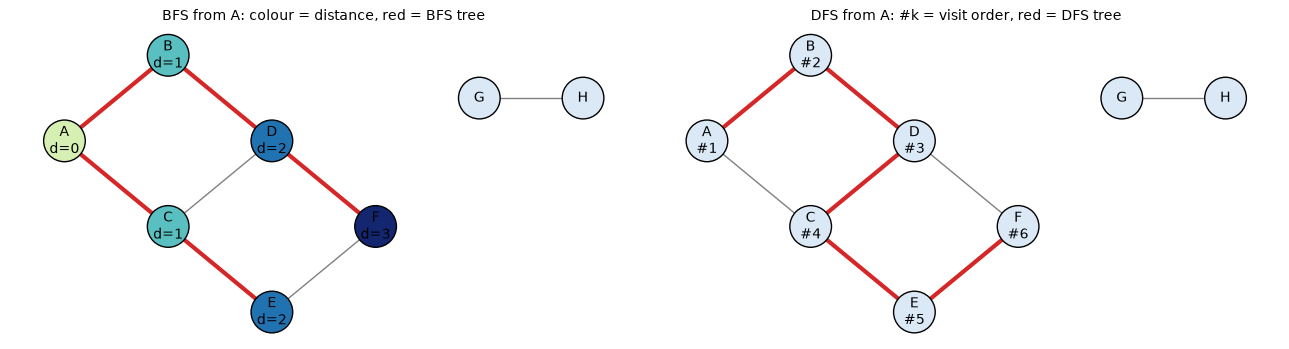

In [6]:
_, bfs_dist, bfs_parent = bfs(ex, "A")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
cmap = plt.cm.YlGnBu
draw_graph(ex, axes[0], EX_POS, "BFS from A: colour = distance, red = BFS tree",
           node_colors={v: cmap(0.2 + 0.25 * d) for v, d in bfs_dist.items()},
           labels={v: f"{v}\nd={bfs_dist[v]}" if v in bfs_dist else v for v in ex.nodes()},
           highlight=[(p, v) for v, p in bfs_parent.items() if p is not None], node_size=900)
dfs_order = dfs_recursive(ex, "A")
dfs_tree = [(dparent[v], v) for v in dfs_order if dparent[v] is not None]
draw_graph(ex, axes[1], EX_POS, "DFS from A: #k = visit order, red = DFS tree",
           labels={v: f"{v}\n#{dfs_order.index(v) + 1}" if v in dfs_order else v for v in ex.nodes()},
           highlight=dfs_tree, node_size=900)
plt.tight_layout(); plt.show()

**What just happened?** DFS from A visits A, B, D, C, E, F: it dives A → B → D → C → E → F along one long path (the red DFS tree on the right), whereas BFS fans out layer by layer (left; the BFS tree reaches every vertex with the fewest edges). The discovery/finish table shows the **parenthesis structure**: each vertex's interval [discovered, finished] is either nested inside or disjoint from another's (D's interval [3, 10] contains C's [4, 9], while A's [1, 12] contains everything in its component; G and H get a separate DFS tree with times 13 to 16). Recursive DFS, iterative DFS and networkx agree exactly on random graphs.

**Complexity:** O(n + m) time; O(n) space for `visited` plus the stack (recursion depth can reach n, hence `sys.setrecursionlimit` or the iterative version for big graphs).

| | BFS | DFS |
|---|---|---|
| Data structure | queue (FIFO) | stack (LIFO) / recursion |
| Order | layer by layer | deep first, then backtrack |
| Shortest paths (unweighted) | **yes** | no |
| Typical uses | shortest hops, levels, bipartite check, web crawling | cycles, topological sort, SCCs, bridges, mazes, backtracking |
| Memory | O(width of the graph) | O(depth of the search) |

🎓 **Exam / interview tip:** in directed graphs DFS classifies every edge (u, v): **tree** (v discovered via this edge), **back** (v is an ancestor still in progress: **a cycle!**), **forward** (v a finished descendant) or **cross** (anything else). "A digraph is acyclic iff DFS finds no back edge" is the key theorem behind the next sections.

<a id="components"></a>
## 5. Connected components, cycle detection and bipartite graphs

> **In plain English:** using BFS/DFS to find separate groups, to spot loops, and to check whether a graph splits cleanly into two sides.

### 5.1 Connected components

Run BFS (or DFS) from every vertex that is not yet visited; each run collects exactly one component. O(n + m) in total.

components of the running example: [['A', 'B', 'C', 'D', 'E', 'F'], ['G', 'H']]


components match networkx on 300 random graphs


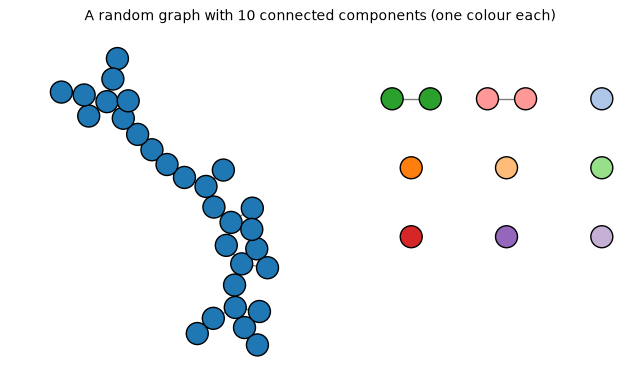

In [7]:
def connected_components(g):
    seen, comps = set(), []
    for s in g.nodes():
        if s in seen:
            continue
        comp, queue = [], deque([s])           # BFS collects one whole component
        seen.add(s)
        while queue:
            u = queue.popleft(); comp.append(u)
            for v in g.neighbors(u):
                if v not in seen:
                    seen.add(v); queue.append(v)
        comps.append(comp)
    return comps

print("components of the running example:", connected_components(ex))
rng = random.Random(3)
for _ in range(300):
    g = random_graph(rng.randint(1, 60), rng.randint(0, 60), rng)
    ours = {frozenset(c) for c in connected_components(g)}
    assert ours == {frozenset(c) for c in nx.connected_components(g.to_networkx())}
print("components match networkx on 300 random graphs")

g = random_graph(40, 32, random.Random(4))
comps = connected_components(g)
colour_of = {v: plt.cm.tab20(i % 20) for i, c in enumerate(comps) for v in c}
fig, ax = plt.subplots(figsize=(8, 4.5))
def component_layout(g, comps):
    '''Lay out each component separately: the biggest on the left, the others in a small grid.'''
    G, pos = g.to_networkx(), {}
    for i, comp in enumerate(sorted(comps, key=len, reverse=True)):
        local = nx.kamada_kawai_layout(G.subgraph(comp)) if len(comp) > 1 else {comp[0]: np.zeros(2)}
        size = 2.5 if i == 0 else 0.3
        cx, cy = (0, 0) if i == 0 else (3.5 + 1.5 * ((i - 1) % 3), 1.8 - 1.2 * ((i - 1) // 3))
        for v, (x, y) in local.items():
            pos[v] = (cx + size * x, cy + size * y)
    return pos

draw_graph(g, ax, component_layout(g, comps), f"A random graph with {len(comps)} connected components (one colour each)",
           node_colors=colour_of, node_size=250, labels={v: "" for v in g.nodes()})
plt.show()

### 5.2 Cycle detection

- **Undirected:** during DFS, if we meet an already-visited neighbour that is **not the parent** we came from, we have found a cycle. (Alternative: a graph with c components is a forest exactly when m = n − c.)
- **Directed:** the parent trick is not enough (two paths can reach the same vertex without a cycle). Use **three colours**: white = unvisited, grey = on the current DFS path, black = finished. An edge to a **grey** vertex is a back edge, i.e. a cycle.

```
undirected: A - B - D - C - A is a cycle         directed: x -> y, x -> z, y -> z has NO cycle
            (D sees visited C, not its parent)              (z is reached twice, but it is black, not grey)
```

In [8]:
def has_cycle_undirected(g):
    visited = set()
    def dfs(u, parent):
        visited.add(u)
        for v in g.neighbors(u):
            if v not in visited:
                if dfs(v, u):
                    return True
            elif v != parent:                  # visited and not where we came from -> cycle
                return True
        return False
    return any(dfs(s, None) for s in g.nodes() if s not in visited)

WHITE, GREY, BLACK = 0, 1, 2

def find_cycle_directed(g):
    '''Return a list of vertices forming a directed cycle, or None if the graph is a DAG.'''
    color = {u: WHITE for u in g.nodes()}
    parent = {}
    def visit(u):
        color[u] = GREY                        # u is on the current path
        for v in g.neighbors(u):
            if color[v] == GREY:               # back edge u -> v: walk parents from u back to v
                cycle, x = [u], u
                while x != v:
                    x = parent[x]; cycle.append(x)
                return cycle[::-1]             # v ... u (and the edge u -> v closes it)
            if color[v] == WHITE:
                parent[v] = u
                found = visit(v)
                if found:
                    return found
        color[u] = BLACK                       # finished: no cycle through u
        return None
    for s in g.nodes():
        if color[s] == WHITE:
            found = visit(s)
            if found:
                return found
    return None

print("running example has a cycle:", has_cycle_undirected(ex))
print("tree-shaped graph has a cycle:", has_cycle_undirected(Graph.from_edges([(1, 2), (1, 3), (3, 4)])))
print("x->y, x->z, y->z directed cycle:", find_cycle_directed(dg))
print("p->q->r->p directed cycle:", find_cycle_directed(cyc))

rng = random.Random(5)
for _ in range(400):
    g = random_graph(rng.randint(1, 30), rng.randint(0, 35), rng)
    G = g.to_networkx()
    expected = len(g.edges()) > len(g.nodes()) - nx.number_connected_components(G)   # not a forest
    assert has_cycle_undirected(g) == expected == (len(nx.cycle_basis(G)) > 0)
    d = random_graph(rng.randint(1, 30), rng.randint(0, 40), rng, directed=True)
    c = find_cycle_directed(d)
    assert (c is None) == nx.is_directed_acyclic_graph(d.to_networkx())
    if c:                                      # the returned cycle must be real
        assert all(c[(i + 1) % len(c)] in d.adj[c[i]] for i in range(len(c)))
print("cycle detection matches networkx on 400 undirected + 400 directed random graphs")

running example has a cycle: True
tree-shaped graph has a cycle: False
x->y, x->z, y->z directed cycle: None
p->q->r->p directed cycle: ['p', 'q', 'r']


cycle detection matches networkx on 400 undirected + 400 directed random graphs


**What just happened?** The running example contains the cycle A-B-D-C-A, while the tree-shaped graph has none. The DAG x→y, x→z, y→z correctly has no directed cycle even though z is reachable two ways, and for p→q→r→p the function returns the actual cycle. Both checks are O(n + m).

### 5.3 Bipartite check (two-colouring)

Colour the start vertex 0; BFS gives every neighbour the opposite colour. If an edge ever joins two vertices of the **same** colour, the graph contains an odd cycle and is **not** bipartite. Applications: matching users to items, scheduling two shifts with conflicts, checking whether a conflict graph can be split in two.

people/skills: {'Ann': 0, 'Python': 1, 'SQL': 1, 'Cat': 0, 'Bob': 0, 'Stats': 1}
4-cycle: {1: 0, 2: 1, 4: 1, 3: 0} | triangle: None
bipartite check matches networkx on 400 random graphs


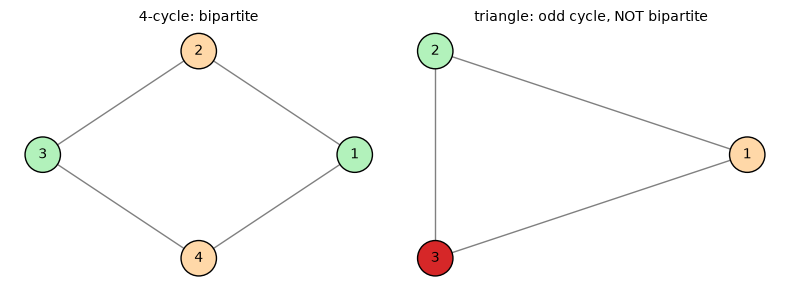

In [9]:
def two_colouring(g):
    '''Return {vertex: 0/1} if g is bipartite, else None.'''
    color = {}
    for s in g.nodes():
        if s in color:
            continue
        color[s] = 0
        queue = deque([s])
        while queue:
            u = queue.popleft()
            for v in g.neighbors(u):
                if v not in color:
                    color[v] = 1 - color[u]        # opposite side
                    queue.append(v)
                elif color[v] == color[u]:         # same side on both ends: odd cycle
                    return None
    return color

square = Graph.from_edges([(1, 2), (2, 3), (3, 4), (4, 1)])   # even cycle
triangle = Graph.from_edges([(1, 2), (2, 3), (3, 1)])         # odd cycle
print("people/skills:", two_colouring(bip))
print("4-cycle:", two_colouring(square), "| triangle:", two_colouring(triangle))

rng = random.Random(6)
for _ in range(400):
    g = random_graph(rng.randint(1, 25), rng.randint(0, 30), rng)
    col = two_colouring(g)
    assert (col is not None) == nx.is_bipartite(g.to_networkx())
    if col:
        assert all(col[u] != col[v] for u, v, _ in g.edges())
print("bipartite check matches networkx on 400 random graphs")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
col = two_colouring(square)
draw_graph(square, axes[0], nx.circular_layout(square.to_networkx()), "4-cycle: bipartite",
           node_colors={v: ("#ffd8a8" if c else "#b2f2bb") for v, c in col.items()})
draw_graph(triangle, axes[1], nx.circular_layout(triangle.to_networkx()), "triangle: odd cycle, NOT bipartite",
           node_colors={1: "#ffd8a8", 2: "#b2f2bb", 3: "tab:red"})
plt.tight_layout(); plt.show()

<a id="topo"></a>
## 6. Topological sort

> **In plain English:** putting tasks in an order where every task comes after the tasks it depends on.

A **topological order** of a DAG lists the vertices so that **every edge goes from left to right** (u before v for every u → v). It exists **if and only if** the graph has no directed cycle. Uses: build systems (compile dependencies first), course prerequisites, spreadsheet recalculation, task schedulers such as Airflow, and the order in which a deep-learning framework evaluates (and, reversed, back-propagates through) its computation graph.

**Kahn's algorithm (1962):** repeatedly output a vertex with **in-degree 0** (nothing left that must come before it) and delete its outgoing edges. If vertices remain but none has in-degree 0, there is a cycle.

**DFS-based:** run DFS; when a vertex **finishes**, prepend it to the answer (i.e. output vertices in **decreasing finish time**). A vertex finishes only after everything it points to has finished, so it ends up before them.

Example: a small ML project.

In [10]:
pipeline = Graph.from_edges([
    ("collect data", "clean data"), ("clean data", "split"), ("clean data", "features"), ("split", "train"),
    ("features", "train"), ("train", "evaluate"), ("split", "evaluate"), ("evaluate", "deploy"), ("write docs", "deploy"),
], directed=True)

def topo_kahn(g, trace=None):
    indeg = {u: 0 for u in g.nodes()}
    for u, v, _ in g.edges():
        indeg[v] += 1
    queue = deque(u for u in g.nodes() if indeg[u] == 0)    # everything with no prerequisites
    order = []
    while queue:
        u = queue.popleft()
        order.append(u)
        for v in g.neighbors(u):
            indeg[v] -= 1                                  # "delete" the edge u -> v
            if indeg[v] == 0:
                queue.append(v)
        if trace is not None:
            trace.append({"output": u, "ready queue": list(queue)})
    return order if len(order) == len(indeg) else None     # None: a cycle blocked some vertices

def topo_dfs(g):
    color, post = {u: WHITE for u in g.nodes()}, []
    def visit(u):
        color[u] = GREY
        for v in g.neighbors(u):
            if color[v] == GREY:
                return False                               # back edge: not a DAG
            if color[v] == WHITE and not visit(v):
                return False
        color[u] = BLACK
        post.append(u)                                     # u finishes after all its successors
        return True
    for u in g.nodes():
        if color[u] == WHITE and not visit(u):
            return None
    return post[::-1]                                      # decreasing finish time

trace = []
print("Kahn :", topo_kahn(pipeline, trace))
display(pd.DataFrame(trace))
print("DFS  :", topo_dfs(pipeline))
print("with a cycle:", topo_kahn(cyc), topo_dfs(cyc))

def is_topological(g, order):
    pos = {v: i for i, v in enumerate(order)}
    return len(order) == len(g.nodes()) and all(pos[u] < pos[v] for u, v, _ in g.edges())

rng = random.Random(7)
for _ in range(300):
    n = rng.randint(1, 30)
    perm = list(range(n)); rng.shuffle(perm)                 # hidden order -> edges only go forward -> a DAG
    edges = set()
    for _ in range(rng.randint(0, 60) if n > 1 else 0):
        i, j = sorted(rng.sample(range(n), 2))                 # i < j: the edge goes "forward"
        edges.add((perm[i], perm[j]))
    dag = Graph.from_edges(sorted(edges), directed=True, nodes=range(n))
    assert is_topological(dag, topo_kahn(dag)) and is_topological(dag, topo_dfs(dag))
    assert nx.is_directed_acyclic_graph(dag.to_networkx())
    d = random_graph(rng.randint(1, 20), rng.randint(0, 30), rng, directed=True)
    is_dag = nx.is_directed_acyclic_graph(d.to_networkx())
    assert (topo_kahn(d) is not None) == (topo_dfs(d) is not None) == is_dag
small = Graph.from_edges([("a", "b"), ("a", "c"), ("b", "d"), ("c", "d")], directed=True)
all_orders = [tuple(o) for o in nx.all_topological_sorts(small.to_networkx())]
print("all topological orders of a->b, a->c, b->d, c->d:", all_orders)
assert tuple(topo_kahn(small)) in all_orders and tuple(topo_dfs(small)) in all_orders
print("both algorithms give valid orders on 300 random DAGs and detect cycles exactly like networkx")

Kahn : ['collect data', 'write docs', 'clean data', 'split', 'features', 'train', 'evaluate', 'deploy']


,output,ready queue
0,collect data,"[write docs, clean data]"
1,write docs,[clean data]
2,clean data,"[split, features]"
3,split,[features]
4,features,[train]
5,train,[evaluate]
6,evaluate,[deploy]
7,deploy,[]


DFS  : ['write docs', 'collect data', 'clean data', 'features', 'split', 'train', 'evaluate', 'deploy']
with a cycle: None None


all topological orders of a->b, a->c, b->d, c->d: [('a', 'c', 'b', 'd'), ('a', 'b', 'c', 'd')]
both algorithms give valid orders on 300 random DAGs and detect cycles exactly like networkx


**What just happened?** Kahn's algorithm started with the two tasks that have no prerequisites ("collect data", "write docs") and released each task as soon as all its prerequisites were done; the DFS version produced a different but equally valid order. A DAG usually has **many** topological orders (the 4-vertex example has 2). On a graph with a cycle both return `None`. Both run in **O(n + m)**.

<a id="shortest"></a>
## 7. Shortest paths

> **In plain English:** finding the cheapest route between places, with different tools depending on what the edge costs look like.

| Situation | Algorithm | Time |
|---|---|---|
| unweighted (all edges cost 1) | **BFS** (section 4) | O(n + m) |
| edge weights 0 or 1 | **0-1 BFS** (deque) | O(n + m) |
| non-negative weights, one source | **Dijkstra** with a binary heap | O((n + m) log n) |
| negative weights allowed, one source; detect negative cycles | **Bellman-Ford** | O(n · m) |
| all pairs, dense graphs, negative weights allowed | **Floyd-Warshall** | O(n³) |

All of them rely on **relaxation**: if `dist[u] + w(u, v) < dist[v]`, we found a better route to v via u, so update `dist[v]` and remember `parent[v] = u`.

### 7.1 Dijkstra's algorithm (1959)

Keep a priority queue of tentative distances. Repeatedly take the **closest unfinished vertex** u; its distance is now **final**; relax all edges leaving u. Why is the popped distance final? Every other route to u would have to leave the finished set through some vertex x with dist[x] ≥ dist[u], and then add **non-negative** weights, so it cannot be shorter.

We use the textbook example from CLRS (directed, source s). Expected result: s 0, t 8, x 9, y 5, z 7.

In [11]:
clrs = Graph.from_edges([("s", "t", 10), ("s", "y", 5), ("t", "x", 1), ("t", "y", 2), ("y", "t", 3), ("y", "x", 9),
                         ("y", "z", 2), ("x", "z", 4), ("z", "x", 6), ("z", "s", 7)], directed=True)

def dijkstra(g, s, trace=None):
    dist, parent = {s: 0}, {s: None}
    done = set()                                    # vertices whose distance is final
    pq = [(0, s)]                                   # (tentative distance, vertex)
    while pq:
        d, u = heapq.heappop(pq)
        if u in done:                               # stale entry (we pushed u again with a smaller key)
            continue
        done.add(u)
        relaxed = []
        for v, w in g.adj[u].items():
            if v in done:
                continue
            if d + w < dist.get(v, INF):            # relaxation
                dist[v], parent[v] = d + w, u
                heapq.heappush(pq, (d + w, v))      # lazy "decrease-key": just push again
                relaxed.append(f"{v}={d + w}")
        if trace is not None:
            trace.append({"pop (final)": f"{u} = {d}", "relaxed": ", ".join(relaxed) or "-",
                          "tentative dist": dict(sorted(dist.items()))})
    return dist, parent

trace = []
dist, parent = dijkstra(clrs, "s", trace)
display(pd.DataFrame(trace))
print("distances:", dict(sorted(dist.items())), "| path s -> x:", path_to(parent, "x"))

rng = random.Random(8)
for _ in range(300):
    directed = rng.random() < 0.5
    g = random_graph(rng.randint(1, 40), rng.randint(0, 120), rng, directed=directed, weight=lambda: rng.randint(0, 20))
    s = rng.randrange(len(g.nodes()))
    d, p = dijkstra(g, s)
    assert d == nx.single_source_dijkstra_path_length(g.to_networkx(), s)
    for t in d:                                     # every reconstructed path really has that length
        path = path_to(p, t)
        assert sum(g.adj[a][b] for a, b in zip(path, path[1:])) == d[t]
print("Dijkstra matches networkx on 300 random weighted (di)graphs, and every path has the reported length")

,pop (final),relaxed,tentative dist
0,s = 0,"t=10, y=5","{'s': 0, 't': 10, 'y': 5}"
1,y = 5,"t=8, x=14, z=7","{'s': 0, 't': 8, 'x': 14, 'y': 5, 'z': 7}"
2,z = 7,x=13,"{'s': 0, 't': 8, 'x': 13, 'y': 5, 'z': 7}"
3,t = 8,x=9,"{'s': 0, 't': 8, 'x': 9, 'y': 5, 'z': 7}"
4,x = 9,-,"{'s': 0, 't': 8, 'x': 9, 'y': 5, 'z': 7}"


distances: {'s': 0, 't': 8, 'x': 9, 'y': 5, 'z': 7} | path s -> x: ['s', 'y', 't', 'x']


Dijkstra matches networkx on 300 random weighted (di)graphs, and every path has the reported length


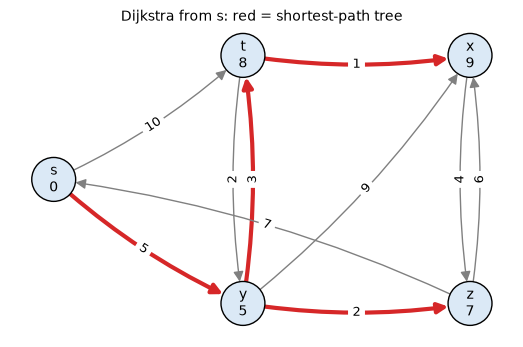

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4))
cpos = {"s": (0, 0.5), "t": (1, 1), "y": (1, 0), "x": (2.2, 1), "z": (2.2, 0)}
draw_graph(clrs, ax, cpos, "Dijkstra from s: red = shortest-path tree", edge_labels=True,
           labels={v: f"{v}\n{dist[v]}" for v in clrs.nodes()},
           highlight=[(p, v) for v, p in parent.items() if p is not None], node_size=1000)
plt.show()

**What just happened?** Vertices were finalised in the order s (0), y (5), z (7), t (8), x (9), exactly as in CLRS. Notice how t was first reached with 10 (directly from s) and later improved to 8 via y. The red edges form the **shortest-path tree**. With a binary heap each push/pop is O(log n) and there are at most m pushes, so the running time is **O((n + m) log n)**; space O(n + m).

### 7.2 Why negative edges break Dijkstra

Dijkstra's argument ("a finished vertex can never get a shorter path later") assumes that extending a path never makes it cheaper. A negative edge violates that. Below, A is finalised with distance 1, but the true shortest path S → B → A costs 3 + (−3) = 0, and T inherits the wrong value.

```
      1          1
  S ----> A ----> T          Dijkstra: A = 1, T = 2      (wrong)
   \     ^                   true:     A = 0, T = 1      via S -> B -> A -> T
  3 \   / -3
     v /
      B
```

⚠️ **Common mistake:** "fixing" negative weights by adding a constant to every edge. That penalises paths with more edges and changes which path is shortest. (Johnson's algorithm re-weights correctly using vertex potentials computed by Bellman-Ford.)

In [13]:
neg = Graph.from_edges([("S", "A", 1), ("S", "B", 3), ("B", "A", -3), ("A", "T", 1)], directed=True)
d_wrong, _ = dijkstra(neg, "S")
d_true = nx.single_source_bellman_ford_path_length(neg.to_networkx(), "S")
print("Dijkstra     :", dict(sorted(d_wrong.items())))
print("correct (BF) :", dict(sorted(d_true.items())))

Dijkstra     : {'A': 1, 'B': 3, 'S': 0, 'T': 2}
correct (BF) : {'A': 0, 'B': 3, 'S': 0, 'T': 1}


### 7.3 Bellman-Ford (1956-58)

Relax **every edge**, n − 1 times. After round k, every shortest path that uses at most k edges is correct; a shortest simple path has at most n − 1 edges, so n − 1 rounds suffice. If a **further** round still improves something, there is a **negative cycle** reachable from the source (going round it forever makes the cost −∞, so "shortest path" is undefined).

O(n · m) time, O(n) space; slower than Dijkstra but it handles negative weights and detects negative cycles. It is the basis of distance-vector routing protocols (RIP) and of arbitrage detection in currency graphs.

In [14]:
def bellman_ford(g, s):
    '''Return (dist, parent, has_negative_cycle) for a directed graph.'''
    dist = {u: INF for u in g.nodes()}
    parent = {u: None for u in g.nodes()}
    dist[s] = 0
    edges = g.edges()
    for _ in range(len(dist) - 1):                  # n - 1 rounds
        changed = False
        for u, v, w in edges:
            if dist[u] + w < dist[v]:               # relaxation (INF + w stays INF)
                dist[v], parent[v] = dist[u] + w, u
                changed = True
        if not changed:                             # early exit: nothing improved
            break
    negative_cycle = any(dist[u] + w < dist[v] for u, v, w in edges)
    return dist, parent, negative_cycle

def has_negative_cycle(g):
    '''Anywhere in the graph: start with dist 0 everywhere (a virtual source joined to all vertices).'''
    dist = {u: 0 for u in g.nodes()}
    edges = g.edges()
    for _ in range(len(dist)):
        for u, v, w in edges:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
    return any(dist[u] + w < dist[v] for u, v, w in edges)

dist, parent, cycle = bellman_ford(neg, "S")
print("Bellman-Ford on the counter-example:", {k: v for k, v in sorted(dist.items())}, "| negative cycle:", cycle,
      "| path to T:", path_to(parent, "T"))
arb = Graph.from_edges([("USD", "EUR", -1), ("EUR", "GBP", 2), ("GBP", "USD", -2)], directed=True)
print("cycle USD -> EUR -> GBP -> USD with total weight -1: negative cycle detected =", bellman_ford(arb, "USD")[2])

def potential_weights(rng, n):
    '''Weights w(u,v) = c + p[u] - p[v] with c >= 0: some are negative, but every cycle sums to >= 0.'''
    p = [rng.randint(-10, 10) for _ in range(n)]
    return lambda u, v: rng.randint(0, 10) + p[u] - p[v]

rng = random.Random(9)
for _ in range(300):
    n = rng.randint(1, 25)
    base = random_graph(n, rng.randint(0, 60), rng, directed=True)
    if rng.random() < 0.6:                          # no negative cycles (but negative edges)
        wf = potential_weights(rng, n)
        g = Graph.from_edges([(u, v, wf(u, v)) for u, v, _ in base.edges()], True, range(n))
    else:                                           # arbitrary weights: negative cycles likely
        g = Graph.from_edges([(u, v, rng.randint(-5, 10)) for u, v, _ in base.edges()], True, range(n))
    G = g.to_networkx()
    assert has_negative_cycle(g) == nx.negative_edge_cycle(G)
    s = rng.randrange(n)
    dist, _, neg_reachable = bellman_ford(g, s)
    if not nx.negative_edge_cycle(G):
        assert not neg_reachable
        assert {k: v for k, v in dist.items() if v < INF} == nx.single_source_bellman_ford_path_length(G, s)
print("Bellman-Ford distances and negative-cycle detection match networkx on 300 random digraphs")

Bellman-Ford on the counter-example: {'A': 0, 'B': 3, 'S': 0, 'T': 1} | negative cycle: False | path to T: ['S', 'B', 'A', 'T']
cycle USD -> EUR -> GBP -> USD with total weight -1: negative cycle detected = True


Bellman-Ford distances and negative-cycle detection match networkx on 300 random digraphs


**What just happened?** Bellman-Ford finds the correct distances A = 0 and T = 1 via S → B → A → T that Dijkstra missed. On the three-currency loop with total weight −1 it reports a negative cycle (with weights −log(exchange rate), such a cycle is a money-making **arbitrage** opportunity). On random graphs it matches networkx, including negative-cycle detection.

### 7.4 Floyd-Warshall (1962): all pairs

Dynamic programming over intermediate vertices: let D_k[i][j] be the shortest i → j distance using only vertices 0..k−1 as intermediate stops. Then

**D_{k+1}[i][j] = min(D_k[i][j], D_k[i][k] + D_k[k][j])**

(either the best path avoids vertex k, or it goes through k once). Three nested loops: **O(n³)** time, **O(n²)** space. Negative edges are fine; a **negative cycle** shows up as D[i][i] < 0. It is simple and fast in practice for dense graphs with up to a few hundred vertices.

In [15]:
def floyd_warshall(g):
    nodes = g.nodes()
    idx = {v: i for i, v in enumerate(nodes)}
    n = len(nodes)
    D = [[0 if i == j else INF for j in range(n)] for i in range(n)]
    nxt = [[None] * n for _ in range(n)]               # next hop, for path reconstruction
    for u, v, w in g.edges():
        i, j = idx[u], idx[v]
        D[i][j], nxt[i][j] = w, j
        if not g.directed:
            D[j][i], nxt[j][i] = w, i
    for i in range(n):
        nxt[i][i] = i
    for k in range(n):                                  # allow vertex k as an intermediate stop
        Dk = D[k]
        for i in range(n):
            dik = D[i][k]
            if dik == INF:
                continue
            Di = D[i]
            for j in range(n):
                if dik + Dk[j] < Di[j]:
                    Di[j] = dik + Dk[j]
                    nxt[i][j] = nxt[i][k]
    return nodes, np.array(D, dtype=float), nxt

def fw_path(nodes, nxt, a, b):
    i, j = nodes.index(a), nodes.index(b)
    if nxt[i][j] is None:
        return None
    path = [i]
    while i != j:
        i = nxt[i][j]; path.append(i)
    return [nodes[k] for k in path]

nodes, D, nxt = floyd_warshall(clrs)
display(pd.DataFrame(D, index=nodes, columns=nodes).astype(int))
print("path x -> t:", fw_path(nodes, nxt, "x", "t"))

rng = random.Random(10)
for _ in range(150):
    n = rng.randint(1, 20)
    base = random_graph(n, rng.randint(0, 60), rng, directed=True)
    wf = potential_weights(rng, n)
    g = Graph.from_edges([(u, v, wf(u, v)) for u, v, _ in base.edges()], True, range(n))
    nodes, D, _ = floyd_warshall(g)
    ref = nx.floyd_warshall_numpy(g.to_networkx(), nodelist=nodes)
    assert np.array_equal(D, ref)
    assert (np.diag(D) < 0).any() == nx.negative_edge_cycle(g.to_networkx())
for _ in range(150):                                    # arbitrary weights: negative cycles likely
    n = rng.randint(1, 15)
    base = random_graph(n, rng.randint(0, 40), rng, directed=True)
    g = Graph.from_edges([(u, v, rng.randint(-5, 10)) for u, v, _ in base.edges()], True, range(n))
    assert (np.diag(floyd_warshall(g)[1]) < 0).any() == nx.negative_edge_cycle(g.to_networkx())
print("Floyd-Warshall matches networkx.floyd_warshall_numpy on 150 random digraphs with negative edges,")
print("and its diagonal test (D[i][i] < 0) detects negative cycles exactly like networkx on 150 more")

,s,t,y,x,z
s,0,8,5,9,7
t,11,0,2,1,4
y,9,3,0,4,2
x,11,19,16,0,4
z,7,15,12,6,0


path x -> t: ['x', 'z', 's', 'y', 't']


Floyd-Warshall matches networkx.floyd_warshall_numpy on 150 random digraphs with negative edges,
and its diagonal test (D[i][i] < 0) detects negative cycles exactly like networkx on 150 more


**What just happened?** The table is the full distance matrix of the CLRS graph: row s reproduces Dijkstra's answers (0, 8, 9, 5, 7) and every other row gives the answers for the other sources, all from one O(n³) computation. The `nxt` matrix rebuilds actual routes, e.g. x → z → s → y → t. The diagonal stays 0, so there is no negative cycle.

### 7.5 0-1 BFS (briefly)

If every weight is **0 or 1** (e.g. "free moves" and "paid moves" on a grid, or reversing an edge costs 1), use a **deque**: push the endpoint of a 0-edge to the **front** and of a 1-edge to the **back**. The deque always holds at most two distinct distances (d and d + 1) in sorted order, so it acts as a priority queue with O(1) operations: **O(n + m)** total.

In [16]:
def zero_one_bfs(g, s):
    dist = {s: 0}
    dq = deque([s])
    while dq:
        u = dq.popleft()
        for v, w in g.adj[u].items():
            if dist[u] + w < dist.get(v, INF):
                dist[v] = dist[u] + w
                if w == 0:
                    dq.appendleft(v)               # same distance: process soon
                else:
                    dq.append(v)                   # distance + 1: process later
    return dist

rng = random.Random(11)
for _ in range(300):
    g = random_graph(rng.randint(1, 40), rng.randint(0, 100), rng, directed=rng.random() < 0.5, weight=lambda: rng.randint(0, 1))
    s = rng.randrange(len(g.nodes()))
    assert zero_one_bfs(g, s) == dijkstra(g, s)[0] == nx.single_source_dijkstra_path_length(g.to_networkx(), s)
print("0-1 BFS == our Dijkstra == networkx on 300 random graphs with 0/1 weights")

0-1 BFS == our Dijkstra == networkx on 300 random graphs with 0/1 weights


<a id="mst"></a>
## 8. Minimum spanning trees (MST) and Union-Find

> **In plain English:** connecting every node as cheaply as possible, with a clever helper that tracks which nodes are already joined.

### 8.1 The problem

You must connect n towns with fibre cable; each possible link has a cost. Which links connect everything for the least total cost? A **spanning tree** of a connected, undirected, weighted graph is a subset of n − 1 edges that connects all vertices without cycles; a **minimum spanning tree** has the smallest total weight. (If the graph is disconnected we get a minimum spanning **forest**.)

**Cut property** (why the greedy algorithms below are correct): split the vertices into any two groups; the cheapest edge crossing between the groups belongs to some MST. Both algorithms keep adding such a "safe" edge.

### 8.2 Union-Find (disjoint-set union)

Kruskal needs to ask "are u and v already connected?" quickly while edges are being added. A **Union-Find** structure keeps a forest of parent pointers, one tree per group:
- `find(x)`: follow parents up to the root (the group's representative). **Path compression**: afterwards, point every vertex on that path straight at the root.
- `union(a, b)`: link one root under the other. **Union by rank**: attach the shorter tree under the taller one, so trees stay shallow.

With both tricks, a sequence of m operations takes O(m · α(n)), where α is the inverse Ackermann function, **at most 4 for any n that fits in the universe**: effectively constant.

In [17]:
class UnionFind:
    def __init__(self, items):
        self.parent = {x: x for x in items}        # every item starts as its own root
        self.rank = {x: 0 for x in items}          # upper bound on the tree height
        self.count = len(self.parent)              # number of separate groups

    def find(self, x):
        root = x
        while self.parent[root] != root:           # 1. walk up to the root
            root = self.parent[root]
        while self.parent[x] != root:              # 2. path compression: re-point the path at the root
            self.parent[x], x = root, self.parent[x]
        return root

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False                           # already in the same group (this edge would make a cycle)
        if self.rank[ra] < self.rank[rb]:          # union by rank: shorter tree goes under taller
            ra, rb = rb, ra
        self.parent[rb] = ra
        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1
        self.count -= 1
        return True

def max_depth(parent):
    def depth(x):
        d = 0
        while parent[x] != x:
            x = parent[x]; d += 1
        return d
    return max(depth(x) for x in parent)

n = 1024
naive = {i: i for i in range(n)}                   # no rank, no compression: union(i, i+1) links root under the other
def naive_find(x):
    while naive[x] != x:
        x = naive[x]
    return x
for i in range(n - 1):
    naive[naive_find(i)] = naive_find(i + 1)
uf = UnionFind(range(n))
for i in range(n - 1):
    uf.union(i, i + 1)
print(f"{n} items joined by a chain of unions: naive tree depth = {max_depth(naive)}, with union by rank + compression = {max_depth(uf.parent)}")

rng = random.Random(12)
for _ in range(200):
    n = rng.randint(1, 60)
    uf, G = UnionFind(range(n)), nx.Graph(); G.add_nodes_from(range(n))
    for _ in range(rng.randint(0, 80)):
        a, b = rng.randrange(n), rng.randrange(n)
        uf.union(a, b); G.add_edge(a, b)
    comps = list(nx.connected_components(G))
    assert uf.count == len(comps)
    comp_of = {v: i for i, c in enumerate(comps) for v in c}
    for _ in range(20):
        a, b = rng.randrange(n), rng.randrange(n)
        assert (uf.find(a) == uf.find(b)) == (comp_of[a] == comp_of[b])
print("Union-Find agrees with networkx connected components on 200 random union sequences")

1024 items joined by a chain of unions: naive tree depth = 1023, with union by rank + compression = 1


Union-Find agrees with networkx connected components on 200 random union sequences


**What just happened?** Joining 1,024 items in a chain without the optimisations produced a tree of depth 1,023 (a linked list: `find` would be O(n)). With union by rank and path compression the depth stayed tiny, and the structure agrees with networkx's connected components.

### 8.3 Kruskal (1956) and Prim (1957; Jarník 1930)

- **Kruskal:** sort all edges by weight; add each edge unless it would form a cycle (Union-Find says both ends are already connected). O(m log m) for sorting + O(m α(n)) for Union-Find.
- **Prim:** grow one tree from a start vertex; repeatedly add the cheapest edge leaving the tree (a min-heap of candidate edges). O(m log n) with a binary heap.

Kruskal is natural for sparse graphs given as edge lists; Prim is like Dijkstra (but the key is the single edge weight, not the path length) and works well on dense graphs.

Kruskal: [('A', 'D', 5), ('C', 'E', 5), ('D', 'F', 6), ('A', 'B', 7), ('B', 'E', 7), ('E', 'G', 9)] total 39
Prim   : [('A', 'D', 5), ('D', 'F', 6), ('A', 'B', 7), ('B', 'E', 7), ('E', 'C', 5), ('E', 'G', 9)] total 39


Kruskal and Prim give exactly networkx's MST on 300 random connected graphs (and Kruskal's forest on disconnected ones)


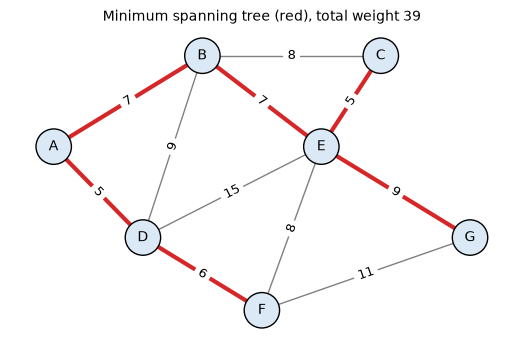

In [18]:
def kruskal(g):
    uf = UnionFind(g.nodes())
    tree, total = [], 0
    for u, v, w in sorted(g.edges(), key=lambda e: e[2]):   # cheapest edges first
        if uf.union(u, v):                                  # joins two different trees -> safe edge
            tree.append((u, v, w)); total += w
    return tree, total

def prim(g, start):
    in_tree = {start}
    tree, total = [], 0
    pq = [(w, start, v) for v, w in g.adj[start].items()]   # candidate edges leaving the tree
    heapq.heapify(pq)
    while pq and len(in_tree) < len(g.adj):
        w, u, v = heapq.heappop(pq)
        if v in in_tree:                                    # both ends already inside: skip (stale)
            continue
        in_tree.add(v)
        tree.append((u, v, w)); total += w
        for x, wx in g.adj[v].items():
            if x not in in_tree:
                heapq.heappush(pq, (wx, v, x))
    return tree, total

towns = Graph.from_edges([("A", "B", 7), ("A", "D", 5), ("B", "C", 8), ("B", "D", 9), ("B", "E", 7), ("C", "E", 5),
                          ("D", "E", 15), ("D", "F", 6), ("E", "F", 8), ("E", "G", 9), ("F", "G", 11)])
kt, ktotal = kruskal(towns)
pt, ptotal = prim(towns, "A")
print("Kruskal:", [(u, v, w) for u, v, w in kt], "total", ktotal)
print("Prim   :", [(u, v, w) for u, v, w in pt], "total", ptotal)

rng = random.Random(13)
for _ in range(300):
    n = rng.randint(1, 40)
    weights = iter(rng.sample(range(1, 10_000), 400))        # distinct weights -> the MST is unique
    g = random_graph(n, rng.randint(n - 1, 3 * n), rng, weight=lambda: next(weights), connected=True)
    ref = nx.minimum_spanning_tree(g.to_networkx())
    ref_edges = {frozenset((u, v)) for u, v in ref.edges()}
    for tree, total in (kruskal(g), prim(g, 0)):
        assert total == ref.size(weight="weight") and {frozenset((u, v)) for u, v, _ in tree} == ref_edges
    forest = random_graph(n, rng.randint(0, n), rng, weight=lambda: rng.randint(1, 20))   # maybe disconnected
    assert kruskal(forest)[1] == nx.minimum_spanning_tree(forest.to_networkx()).size(weight="weight")
print("Kruskal and Prim give exactly networkx's MST on 300 random connected graphs (and Kruskal's forest on disconnected ones)")

tpos = {"A": (0, 1), "B": (1, 2), "C": (2.2, 2), "D": (0.6, 0), "E": (1.8, 1), "F": (1.4, -0.8), "G": (2.8, 0)}
fig, ax = plt.subplots(figsize=(6.5, 4))
draw_graph(towns, ax, tpos, f"Minimum spanning tree (red), total weight {ktotal}", highlight=[(u, v) for u, v, _ in kt], edge_labels=True)
plt.show()

**What just happened?** Both algorithms chose the same 6 edges (n − 1 for 7 towns) with total weight 39, Kruskal in increasing weight order and Prim growing outwards from A. With distinct weights the MST is unique, and on random graphs both reproduced networkx's MST edge-for-edge.

<a id="scc"></a>
## 9. Strongly connected components, bridges and articulation points

> **In plain English:** finding groups where everyone can reach everyone, and single links or nodes whose failure would split a network.

### 9.1 Strongly connected components (SCCs)

In a digraph, u and v are **strongly connected** if each can reach the other. The **SCCs** are the maximal groups of mutually reachable vertices. Shrinking each SCC to a single vertex gives the **condensation**, which is always a **DAG**. Uses: finding clusters of web pages that link to each other, deadlock detection, simplifying dependency graphs, 2-SAT solving.

- **Kosaraju (two passes):** (1) DFS on G and record vertices by finishing time; (2) DFS on the **reversed** graph, starting from vertices in decreasing finishing time; each DFS tree in pass 2 is one SCC. O(n + m).
- **Tarjan (one pass):** a single DFS keeping a stack and, for every vertex, a **low-link** value = the smallest discovery index reachable from its subtree using at most one back edge to a vertex still on the stack. When `low[v] == index[v]`, v is the root of an SCC: pop the stack down to v. O(n + m).

Kosaraju: [['g', 'j', 'i', 'h'], ['k'], ['a', 'c', 'b'], ['d', 'f', 'e']]
Tarjan  : [['f', 'e', 'd'], ['c', 'b', 'a'], ['k'], ['j', 'i', 'h', 'g']]


Kosaraju and Tarjan both match networkx SCCs on 300 random digraphs


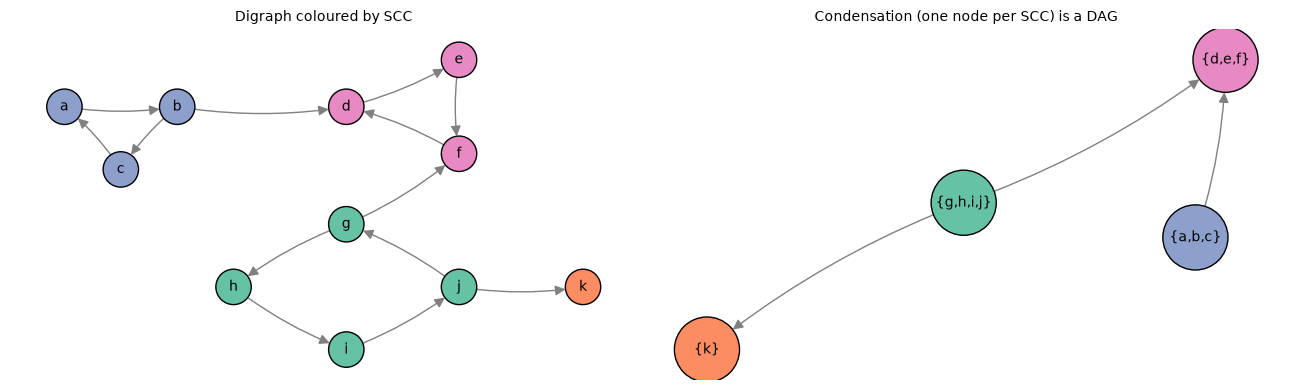

In [19]:
def kosaraju(g):
    visited, finish = set(), []
    def dfs1(u):
        visited.add(u)
        for v in g.neighbors(u):
            if v not in visited:
                dfs1(v)
        finish.append(u)                             # record when u finishes
    for u in g.nodes():
        if u not in visited:
            dfs1(u)
    rev, comp_id, comps = g.reversed(), {}, []
    def dfs2(u, comp):
        comp_id[u] = len(comps)
        comp.append(u)
        for v in rev.neighbors(u):
            if v not in comp_id:
                dfs2(v, comp)
    for u in reversed(finish):                       # decreasing finishing time
        if u not in comp_id:
            comp = []
            dfs2(u, comp)
            comps.append(comp)
    return comps

def tarjan(g):
    index, low, on_stack, stack, comps, counter = {}, {}, set(), [], [], [0]
    def strongconnect(v):
        index[v] = low[v] = counter[0]; counter[0] += 1
        stack.append(v); on_stack.add(v)
        for w in g.neighbors(v):
            if w not in index:                       # tree edge: recurse, then inherit its low-link
                strongconnect(w)
                low[v] = min(low[v], low[w])
            elif w in on_stack:                      # edge back into the current SCC candidate
                low[v] = min(low[v], index[w])
        if low[v] == index[v]:                       # v is the root of an SCC: pop it off
            comp = []
            while True:
                w = stack.pop(); on_stack.discard(w); comp.append(w)
                if w == v:
                    break
            comps.append(comp)
    for v in g.nodes():
        if v not in index:
            strongconnect(v)
    return comps

web = Graph.from_edges([("a", "b"), ("b", "c"), ("c", "a"), ("b", "d"), ("d", "e"), ("e", "f"), ("f", "d"),
                        ("g", "f"), ("g", "h"), ("h", "i"), ("i", "j"), ("j", "g"), ("j", "k")], directed=True)
print("Kosaraju:", kosaraju(web))
print("Tarjan  :", tarjan(web))

rng = random.Random(14)
for _ in range(300):
    g = random_graph(rng.randint(1, 50), rng.randint(0, 100), rng, directed=True)
    ref = {frozenset(c) for c in nx.strongly_connected_components(g.to_networkx())}
    assert {frozenset(c) for c in kosaraju(g)} == ref == {frozenset(c) for c in tarjan(g)}
print("Kosaraju and Tarjan both match networkx SCCs on 300 random digraphs")

comps = kosaraju(web)
cid = {v: i for i, c in enumerate(comps) for v in c}
cond = Graph(directed=True)
for i in range(len(comps)):
    cond.add_node(i)
for u, v, _ in web.edges():
    if cid[u] != cid[v]:
        cond.add_edge(cid[u], cid[v])
assert nx.is_directed_acyclic_graph(cond.to_networkx())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
WEB_POS = {"a": (0, 2), "b": (1, 2), "c": (0.5, 1.2), "d": (2.5, 2), "e": (3.5, 2.6), "f": (3.5, 1.4),
           "g": (2.5, 0.5), "h": (1.5, -0.3), "i": (2.5, -1.1), "j": (3.5, -0.3), "k": (4.6, -0.3)}
draw_graph(web, axes[0], WEB_POS, "Digraph coloured by SCC",
           node_colors={v: plt.cm.Set2(cid[v]) for v in web.nodes()})
draw_graph(cond, axes[1], nx.spring_layout(cond.to_networkx(), seed=1), "Condensation (one node per SCC) is a DAG",
           node_colors={i: plt.cm.Set2(i) for i in range(len(comps))},
           labels={i: "{" + ",".join(sorted(c)) + "}" for i, c in enumerate(comps)}, node_size=2200)
plt.tight_layout(); plt.show()

**What just happened?** The digraph has 4 SCCs: {a, b, c}, {d, e, f}, {g, h, i, j} and {k}. Kosaraju lists them in topological order of the condensation (sources first), Tarjan in reverse topological order; the *sets* are identical and match networkx on random digraphs. The condensation on the right is a DAG, as the theory guarantees.

### 9.2 Bridges and articulation points (briefly)

In an undirected graph, a **bridge** is an edge whose removal disconnects the graph, and an **articulation point** (cut vertex) is a vertex whose removal does so. They reveal single points of failure in networks (a road, a router, a person bridging two communities). One DFS with discovery times `disc` and low-links `low` (smallest discovery time reachable from a subtree using one back edge) finds both in O(n + m):
- tree edge (u, v) is a **bridge** iff `low[v] > disc[u]` (v's subtree cannot climb back to u or above);
- a non-root u is an **articulation point** iff some child v has `low[v] >= disc[u]`; the root is one iff it has ≥ 2 DFS children.

bridges: [(5, 6), (1, 3)] | articulation points: [1, 3, 5]


bridges and articulation points match networkx on 300 random graphs


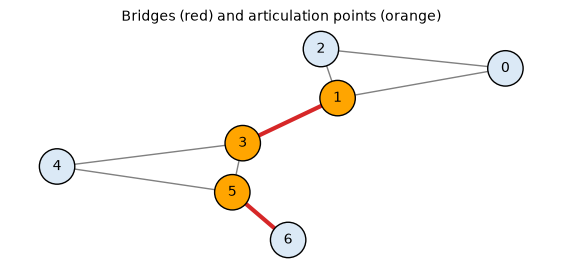

In [20]:
def bridges_and_cut_vertices(g):
    disc, low, clock = {}, {}, [0]
    bridges, cuts = [], set()
    def dfs(u, parent):
        disc[u] = low[u] = clock[0]; clock[0] += 1
        children = 0
        for v in g.neighbors(u):
            if v not in disc:
                children += 1
                dfs(v, u)
                low[u] = min(low[u], low[v])
                if low[v] > disc[u]:
                    bridges.append((u, v))
                if parent is not None and low[v] >= disc[u]:
                    cuts.add(u)
            elif v != parent:                      # back edge
                low[u] = min(low[u], disc[v])
        if parent is None and children > 1:
            cuts.add(u)
    for u in g.nodes():
        if u not in disc:
            dfs(u, None)
    return bridges, cuts

net = Graph.from_edges([(0, 1), (1, 2), (2, 0), (1, 3), (3, 4), (4, 5), (5, 3), (5, 6)])
br, cv = bridges_and_cut_vertices(net)
print("bridges:", br, "| articulation points:", sorted(cv))

rng = random.Random(15)
for _ in range(300):
    g = random_graph(rng.randint(1, 40), rng.randint(0, 60), rng)
    G = g.to_networkx()
    b, c = bridges_and_cut_vertices(g)
    assert {frozenset(e) for e in b} == {frozenset(e) for e in nx.bridges(G)}
    assert c == set(nx.articulation_points(G))
print("bridges and articulation points match networkx on 300 random graphs")
fig, ax = plt.subplots(figsize=(7, 3))
draw_graph(net, ax, nx.kamada_kawai_layout(net.to_networkx()), "Bridges (red) and articulation points (orange)",
           highlight=br, node_colors={v: "orange" for v in cv})
plt.show()

<a id="grids"></a>
## 10. Grid graphs

> **In plain English:** a grid (like a game map or an image) is a graph in disguise, so BFS solves grid puzzles too.

Many puzzles, game maps, images and robot-navigation problems are **grids**. A grid is a graph *without storing any edges*: cell (r, c) is a vertex and its neighbours are the 4 cells up/down/left/right (or 8 with diagonals) that lie inside the grid. All of BFS/DFS applies directly.

### 10.1 Number of islands

Given a grid of 1 (land) and 0 (water), count the islands (groups of land connected horizontally or vertically). Scan every cell; each time we find unvisited land, increase the counter and **flood-fill** the whole island with BFS. This is exactly "count connected components", and also how image-editing "paint bucket" tools and connected-component labelling in computer vision work. O(R · C).

islands: 27 | networkx says: 27


num_islands matches networkx on 200 random grids


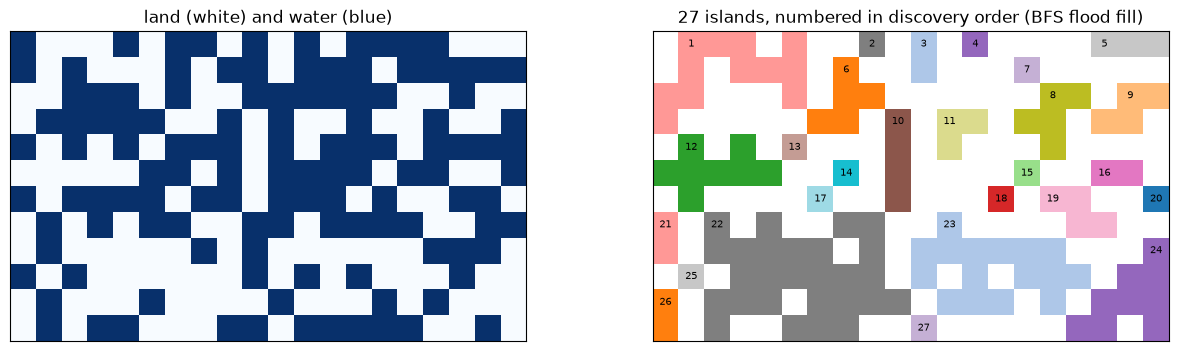

In [21]:
DIRS4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def num_islands(grid):
    R, C = len(grid), len(grid[0])
    label = [[0] * C for _ in range(R)]               # 0 = water/unlabelled, k = island number k
    count = 0
    for r in range(R):
        for c in range(C):
            if grid[r][c] == 1 and label[r][c] == 0:
                count += 1                            # a new island: flood-fill it
                label[r][c] = count
                queue = deque([(r, c)])
                while queue:
                    y, x = queue.popleft()
                    for dy, dx in DIRS4:
                        ny, nx_ = y + dy, x + dx
                        if 0 <= ny < R and 0 <= nx_ < C and grid[ny][nx_] == 1 and label[ny][nx_] == 0:
                            label[ny][nx_] = count
                            queue.append((ny, nx_))
    return count, label

def islands_networkx(grid):
    R, C = len(grid), len(grid[0])
    G = nx.grid_2d_graph(R, C)                       # every cell joined to its 4 neighbours
    land = [(r, c) for r in range(R) for c in range(C) if grid[r][c] == 1]
    return nx.number_connected_components(G.subgraph(land))

rng = np.random.default_rng(16)
grid = (rng.random((12, 20)) < 0.45).astype(int).tolist()
count, label = num_islands(grid)
print("islands:", count, "| networkx says:", islands_networkx(grid))

rr = random.Random(16)
for _ in range(200):
    R, C = rr.randint(1, 15), rr.randint(1, 15)
    g_ = [[int(rr.random() < rr.random()) for _ in range(C)] for _ in range(R)]
    assert num_islands(g_)[0] == islands_networkx(g_)
print("num_islands matches networkx on 200 random grids")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].imshow(grid, cmap="Blues_r"); axes[0].set_title("land (white) and water (blue)")
lab = np.array(label, dtype=float)
colour_idx = np.where(lab > 0, (lab * 7) % 20, np.nan)        # spread consecutive labels over the palette
axes[1].imshow(colour_idx, cmap="tab20", vmin=0, vmax=19)
first_cell = {}
for r in range(len(label)):
    for c in range(len(label[0])):
        if label[r][c]:
            first_cell.setdefault(label[r][c], (r, c))
for k, (r, c) in first_cell.items():                           # write the island number on its first cell
    axes[1].text(c, r, str(k), ha="center", va="center", fontsize=7)
axes[1].set_title(f"{count} islands, numbered in discovery order (BFS flood fill)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 10.2 Rotting oranges (multi-source BFS)

Each cell is empty (0), a fresh orange (1) or a rotten orange (2). Every minute, rotten oranges rot their 4 neighbours. How many minutes until no fresh orange remains (−1 if some can never rot)?

**Multi-source BFS:** put **all** rotten oranges in the queue at time 0. BFS then spreads from all of them simultaneously, and the time a cell is reached is the minute it rots. The answer is the largest such time. Same idea: distance to the nearest hospital for every house, fire spreading in a forest, the "distance transform" in image processing. O(R · C).

minutes until everything is rotten: 5 | brute-force simulation: 5
unreachable orange example: -1


multi-source BFS matches minute-by-minute simulation on 300 random grids


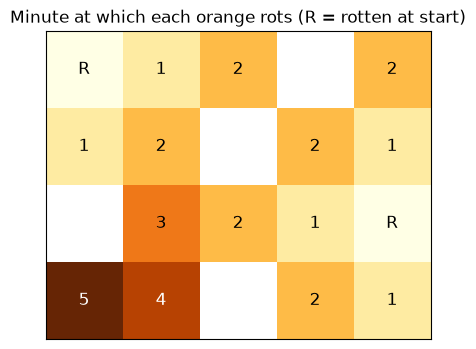

In [22]:
def rotting_oranges(grid):
    R, C = len(grid), len(grid[0])
    time = [[None] * C for _ in range(R)]
    queue = deque()
    for r in range(R):
        for c in range(C):
            if grid[r][c] == 2:                       # every rotten orange is a source at minute 0
                time[r][c] = 0
                queue.append((r, c))
    while queue:
        y, x = queue.popleft()
        for dy, dx in DIRS4:
            ny, nx_ = y + dy, x + dx
            if 0 <= ny < R and 0 <= nx_ < C and grid[ny][nx_] == 1 and time[ny][nx_] is None:
                time[ny][nx_] = time[y][x] + 1        # rots one minute after its neighbour
                queue.append((ny, nx_))
    if any(grid[r][c] == 1 and time[r][c] is None for r in range(R) for c in range(C)):
        return -1, time                               # some fresh orange is unreachable
    return max([t for row in time for t in row if t is not None], default=0), time

def rotting_brute(grid):
    g, minutes = [row[:] for row in grid], 0
    while True:
        to_rot = [(r, c) for r in range(len(g)) for c in range(len(g[0])) if g[r][c] == 1 and
                  any(0 <= r + dy < len(g) and 0 <= c + dx < len(g[0]) and g[r + dy][c + dx] == 2 for dy, dx in DIRS4)]
        if not to_rot:
            return -1 if any(1 in row for row in g) else minutes
        for r, c in to_rot:
            g[r][c] = 2
        minutes += 1

box = [[2, 1, 1, 0, 1],
       [1, 1, 0, 1, 1],
       [0, 1, 1, 1, 2],
       [1, 1, 0, 1, 1]]
minutes, rot_time = rotting_oranges(box)
print("minutes until everything is rotten:", minutes, "| brute-force simulation:", rotting_brute(box))
print("unreachable orange example:", rotting_oranges([[2, 1, 1], [0, 1, 1], [1, 0, 1]])[0])

rr = random.Random(17)
for _ in range(300):
    R, C = rr.randint(1, 8), rr.randint(1, 8)
    g_ = [[rr.choice([0, 1, 1, 1, 2]) for _ in range(C)] for _ in range(R)]
    assert rotting_oranges(g_)[0] == rotting_brute(g_)
print("multi-source BFS matches minute-by-minute simulation on 300 random grids")

fig, ax = plt.subplots(figsize=(5.5, 4))
T = np.array([[np.nan if t is None else t for t in row] for row in rot_time], dtype=float)
ax.imshow(T, cmap="YlOrBr")
for r in range(len(box)):
    for c in range(len(box[0])):
        txt = "" if box[r][c] == 0 else "R" if box[r][c] == 2 else "never" if np.isnan(T[r, c]) else int(T[r, c])
        ax.text(c, r, txt, ha="center", va="center", fontsize=12,
                color="white" if box[r][c] == 1 and not np.isnan(T[r, c]) and T[r, c] >= 4 else "black")
ax.set_title("Minute at which each orange rots (R = rotten at start)"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

**What just happened?** In the example two oranges start rotten (top-left and the right edge) and the rot spreads from both at once; the last orange, in the bottom-left corner, has to be reached the long way round and rots at minute 5 (the brute-force simulation agrees). In the second grid the orange in the bottom-left corner is walled off by empty cells, so the answer is −1. On random grids BFS matched the slow simulation every time.

<a id="summary"></a>
## 11. Complexity summary

> **In plain English:** one table with the speed of every algorithm in this notebook, for quick revision.

| Algorithm | Time | Extra space | Notes |
|---|---|---|---|
| Adjacency matrix / list / edge list | | Θ(n²) / Θ(n + m) / Θ(m) | |
| BFS, DFS (recursive or iterative) | O(n + m) | O(n) | BFS: shortest paths when unweighted |
| Connected components | O(n + m) | O(n) | |
| Cycle detection (undirected / directed) | O(n + m) | O(n) | parent check / white-grey-black colours |
| Bipartite check | O(n + m) | O(n) | BFS 2-colouring |
| Topological sort (Kahn / DFS) | O(n + m) | O(n) | only for DAGs |
| Dijkstra (binary heap) | O((n + m) log n) | O(n + m) | non-negative weights only |
| Bellman-Ford | O(n · m) | O(n) | negative weights, detects negative cycles |
| Floyd-Warshall | O(n³) | O(n²) | all pairs, negative weights OK |
| 0-1 BFS | O(n + m) | O(n) | weights 0 or 1 |
| Union-Find (rank + compression) | O(α(n)) amortised per op | O(n) | α(n) ≤ 4 in practice |
| Kruskal | O(m log m) | O(n + m) | sorting dominates |
| Prim (binary heap) | O(m log n) | O(n + m) | |
| Kosaraju / Tarjan SCC | O(n + m) | O(n + m) / O(n) | Kosaraju needs the reversed graph |
| Bridges and articulation points | O(n + m) | O(n) | one DFS with low-links |
| Grid BFS (islands, oranges) | O(R · C) | O(R · C) | n = R · C, m ≤ 4n |

<a id="modern-ai"></a>
## 12. 🔗 Connections: classical AI search and modern AI

> **In plain English:** the same algorithms power classical AI search, graph neural networks, knowledge graphs and AI agent workflows.

**Classical AI.** Search problems in AI (route finding, puzzles such as the 8-puzzle, planning) are graphs whose vertices are *states* and whose edges are *actions*; the graph is usually generated on the fly instead of stored. BFS, DFS, iterative deepening and **uniform-cost search** (which is Dijkstra's algorithm with early stopping at the goal) are covered as *uninformed search* in [Classical AI: uninformed search](../classical_ai/02_uninformed_search.ipynb); A* adds a heuristic to Dijkstra to aim at the goal: see [Classical AI: informed search](../classical_ai/03_informed_search.ipynb).

**Modern AI.**
- **Graph neural networks** pass messages along the edges of an adjacency list (or multiply by a sparse adjacency matrix): see [GNNs](../../05_Deep_Learning/07_gnn.ipynb).
- **Knowledge graphs and graph databases** store facts as labelled directed edges and answer questions with traversals and path queries; GraphRAG uses them to ground LLM answers: see [knowledge graphs](../../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb) and [graph databases](../../13_Databases/07_graph_databases/01_graph_databases.ipynb).
- **Agent workflows** in LangGraph are directed graphs of steps; loops are cycles and conditional edges are branches: see [LangGraph](../../10_Agents/03_langgraph.ipynb).
- **Computation graphs:** a neural network is a DAG of operations; the forward pass runs in topological order and backpropagation in reverse topological order: see [neural-network fundamentals](../../05_Deep_Learning/01_neural_network_fundamentals.ipynb). Pipeline orchestrators (Airflow, Kubeflow, Prefect) schedule ML jobs as DAGs: see [orchestration](../../15_MLOps/03_pipeline_orchestration/01_orchestration.ipynb).
- **Vector search:** the HNSW index used by most vector databases is a layered proximity graph explored with a greedy best-first search: see [vector databases](../../13_Databases/03_vector_db/01_vector_databases.ipynb).
- **Recommendation systems** model users and items as a bipartite graph and use random walks or GNNs on it: see [recommendation systems](../../03_Machine_Learning/09_recommendation_systems/01_recommendation_systems.ipynb).

<a id="recap"></a>
## 13. Recap

> **In plain English:** the key ideas in a few bullets, then practice problems to check you really understood them.

- A graph is vertices + edges; it can be directed or undirected, weighted or not. Know degree, path, cycle, connected/strongly connected components, DAG, bipartite.
- Use an **adjacency list** for sparse graphs (Θ(n + m) space), an **adjacency matrix** for dense graphs or O(1) edge tests (Θ(n²)), an **edge list** for edge-centric algorithms.
- **BFS** (queue) explores in layers and finds unweighted shortest paths; **DFS** (stack/recursion) dives deep and produces discovery/finish times. Both are O(n + m).
- DFS/BFS solve **components**, **cycle detection** (parent check undirected, grey vertices directed), **bipartite** checks and **topological sort** (also Kahn's in-degree algorithm).
- Shortest paths: **Dijkstra** (non-negative weights, heap), **Bellman-Ford** (negative weights, negative-cycle detection), **Floyd-Warshall** (all pairs, O(n³)), **0-1 BFS** (deque).
- MST: **Kruskal** (sort + **Union-Find** with path compression and union by rank) and **Prim** (heap), both justified by the cut property.
- **SCCs** (Kosaraju, Tarjan) shrink a digraph to a DAG; **bridges/articulation points** find single points of failure; **grids** are implicit graphs for BFS/flood fill.

## Practice problems

**1. (Easy, conceptual)** A social network has 1,000,000 users and each user has on average 200 friends. Estimate the memory of an adjacency matrix (1 bit per cell) and of an adjacency list (8 bytes per stored neighbour). Which would you use?

<details><summary>Show solution</summary>

Matrix: 10⁶ × 10⁶ = 10¹² bits = 1.25 × 10¹¹ bytes ≈ **125 GB**. List: each friendship is stored twice, 2 × (10⁶ × 200 / 2) = 2 × 10⁸ entries × 8 bytes ≈ **1.6 GB**. The graph is sparse (each row of the matrix would be 99.98 % zeros), so the **adjacency list** is the right choice.
</details>

**2. (Easy, by hand)** Run Dijkstra from A on the undirected graph with edges A-B 4, A-C 2, B-C 1, B-D 5, C-D 8, C-E 10, D-E 2, D-F 6, E-F 3. In which order are vertices finalised, and what is the shortest path to F?

<details><summary>Show solution</summary>

Finalisation order with distances: **A 0, C 2, B 3, D 8, E 10, F 13**. (B improves from 4 to 3 via C; D = 3 + 5 = 8 beats 2 + 8 = 10; E = 8 + 2 = 10 beats 12; F = 10 + 3 = 13 beats 8 + 6 = 14.) Shortest path to F: **A → C → B → D → E → F** with cost 2 + 1 + 5 + 2 + 3 = 13. (Checked with code.)
</details>

**3. (Easy, coding)** Given n vertices, an undirected edge list, a source and a destination, return whether a path exists. Use Union-Find.

<details><summary>Show solution</summary>

```python
def valid_path(n, edges, source, destination):
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]        # path halving (a simple form of compression)
            x = parent[x]
        return x
    for u, v in edges:
        parent[find(u)] = find(v)                # union
    return find(source) == find(destination)
```
(Tested against `networkx.has_path` on 500 random graphs.) BFS from the source works too; Union-Find is handy when edges arrive one at a time.
</details>

**4. (Medium, coding)** *Course schedule:* `prerequisites[i] = [a, b]` means course b must be taken before course a. Return a valid order of all courses, or `[]` if impossible.

<details><summary>Show solution</summary>

Kahn's algorithm on the graph with edges b → a:
```python
from collections import deque

def course_order(num_courses, prerequisites):
    graph = [[] for _ in range(num_courses)]
    indeg = [0] * num_courses
    for course, pre in prerequisites:            # pre must be taken before course: edge pre -> course
        graph[pre].append(course)
        indeg[course] += 1
    queue = deque(c for c in range(num_courses) if indeg[c] == 0)
    order = []
    while queue:
        c = queue.popleft(); order.append(c)
        for nxt in graph[c]:
            indeg[nxt] -= 1
            if indeg[nxt] == 0:
                queue.append(nxt)
    return order if len(order) == num_courses else []
```
(Tested on 500 random instances: the order is valid whenever networkx says the graph is a DAG, and `[]` otherwise.)
</details>

**5. (Medium, coding)** *Network delay time:* signals travel along directed weighted edges `times[i] = [u, v, w]` (nodes 1..n) from node k. How long until every node has received the signal (−1 if some never do)?

<details><summary>Show solution</summary>

The answer is the largest shortest-path distance from k, so run Dijkstra:
```python
import heapq

def network_delay_time(times, n, k):
    graph = {u: [] for u in range(1, n + 1)}
    for u, v, w in times:
        graph[u].append((v, w))
    dist = {}
    pq = [(0, k)]
    while pq:
        d, u = heapq.heappop(pq)
        if u in dist:
            continue                              # already finalised
        dist[u] = d
        for v, w in graph[u]:
            if v not in dist:
                heapq.heappush(pq, (d + w, v))
    return max(dist.values()) if len(dist) == n else -1
```
(Tested against networkx on 500 random graphs.)
</details>

**6. (Medium, conceptual)** (a) Why does BFS find shortest paths in an unweighted graph but DFS does not? (b) Can Dijkstra be used on a graph whose only negative edges leave the source? (c) What happens to Kruskal's algorithm if all edge weights are multiplied by −1?

<details><summary>Show solution</summary>

(a) BFS dequeues vertices in non-decreasing order of distance (all of layer d before layer d + 1), so the first time a vertex is discovered is via a shortest path. DFS may first reach a vertex along a long detour and never revisit it.
(b) **Yes.** The source is finalised first with distance 0; its outgoing edges are relaxed once, and from then on only non-negative edges are relaxed, so the "finished distances never improve" argument still holds. (Any other negative edge can break it.)
(c) It computes a **maximum** spanning tree of the original weights (the greedy cut argument works for any ordering), which is useful e.g. for maximum-reliability networks and Chow-Liu trees in probabilistic ML.
</details>

**7. (Hard, coding)** *Cheapest flights within k stops:* given directed flights `[u, v, price]`, find the cheapest price from `src` to `dst` using **at most k stops** (k + 1 flights), or −1.

<details><summary>Show solution</summary>

Plain Dijkstra fails because a cheaper route may use too many stops. Bellman-Ford limited to k + 1 rounds works, if each round only extends paths by **one** flight (hence the copy of the array):
```python
def cheapest_flight(n, flights, src, dst, k):
    INF = float("inf")
    cost = [INF] * n
    cost[src] = 0
    for _ in range(k + 1):                        # at most k stops = at most k + 1 flights
        new = cost[:]                             # copy: each round adds exactly one more flight
        for u, v, price in flights:
            if cost[u] + price < new[v]:
                new[v] = cost[u] + price
        cost = new
    return cost[dst] if cost[dst] < INF else -1
```
O(k · m) time. For the classic example (0→1 100, 1→2 100, 2→0 100, 1→3 600, 2→3 200; k = 1) the answer is 700 via 0 → 1 → 3. (Tested against brute-force enumeration of all routes on 400 random small graphs.)
</details>

## Further reading

- CLRS, *Introduction to Algorithms*, 4th ed. (2022): Ch. 19 "Data Structures for Disjoint Sets", Ch. 20 "Elementary Graph Algorithms" (BFS, DFS, topological sort, SCCs), Ch. 21 "Minimum Spanning Trees", Ch. 22 "Single-Source Shortest Paths", Ch. 23 "All-Pairs Shortest Paths". (In the 3rd edition these are Ch. 21 to 25.)
- Sedgewick and Wayne, *Algorithms*, 4th ed.: Ch. 4 "Graphs" (§1.5 for Union-Find). Free companion site: algs4.cs.princeton.edu.
- Kleinberg and Tardos, *Algorithm Design*: Ch. 3 "Graphs" and Ch. 4 "Greedy Algorithms" (Dijkstra, MST).
- Russell and Norvig, *Artificial Intelligence: A Modern Approach* (4th ed.), Ch. 3 "Solving Problems by Searching" (BFS/DFS/uniform-cost search as AI search).
- Free online: the networkx documentation (algorithms reference), cp-algorithms.com (graph section), VisuAlgo (visualgo.net) animations of graph traversals, shortest paths and MSTs.

## Next notebook

➡️ [08 · Greedy Algorithms and Divide and Conquer](08_greedy_and_divide_and_conquer.ipynb): Kruskal, Prim and Dijkstra were greedy algorithms; next we study when greedy choices are provably optimal, and the divide-and-conquer paradigm.